# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Hilal Tsabitul Azmi Arba'i | 5054251008 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device yang digunakan:", device)
print("PyTorch version:", torch.__version__)

Device yang digunakan: cpu
PyTorch version: 2.14.1+cpu


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

DATA_DIR = "/home/hilal/kuliah/ML/Modul-Praktikum-ML-RKA/8. Deep Learning"
train_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_train.csv", dtype=np.uint8)
test_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_test.csv", dtype=np.uint8)

print("Ukuran data train:", train_df.shape)
print("Ukuran data test :", test_df.shape)
display(train_df.head())

Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


{0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}


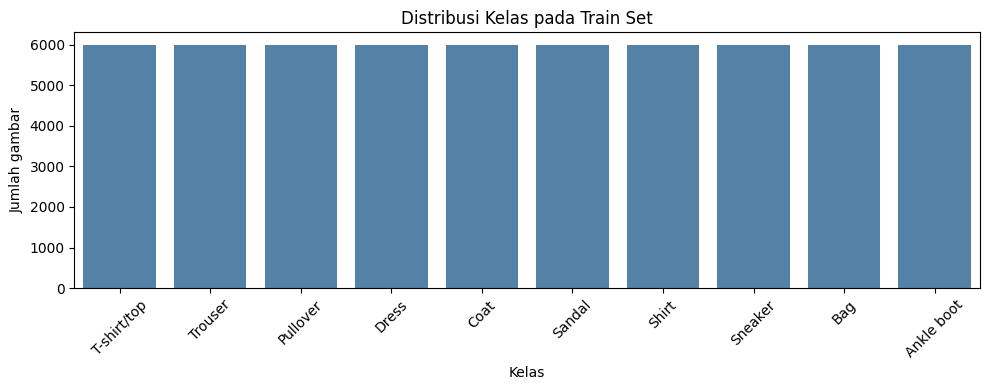

label
T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: count, dtype: int64


In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
label_map = {i: name for i, name in enumerate(class_names)}
print(label_map)

counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
sns.barplot(x=[label_map[i] for i in counts.index], y=counts.values, color="steelblue")
plt.title("Distribusi Kelas pada Train Set")
plt.xlabel("Kelas"); plt.ylabel("Jumlah gambar")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()
print(counts.rename(index=label_map))

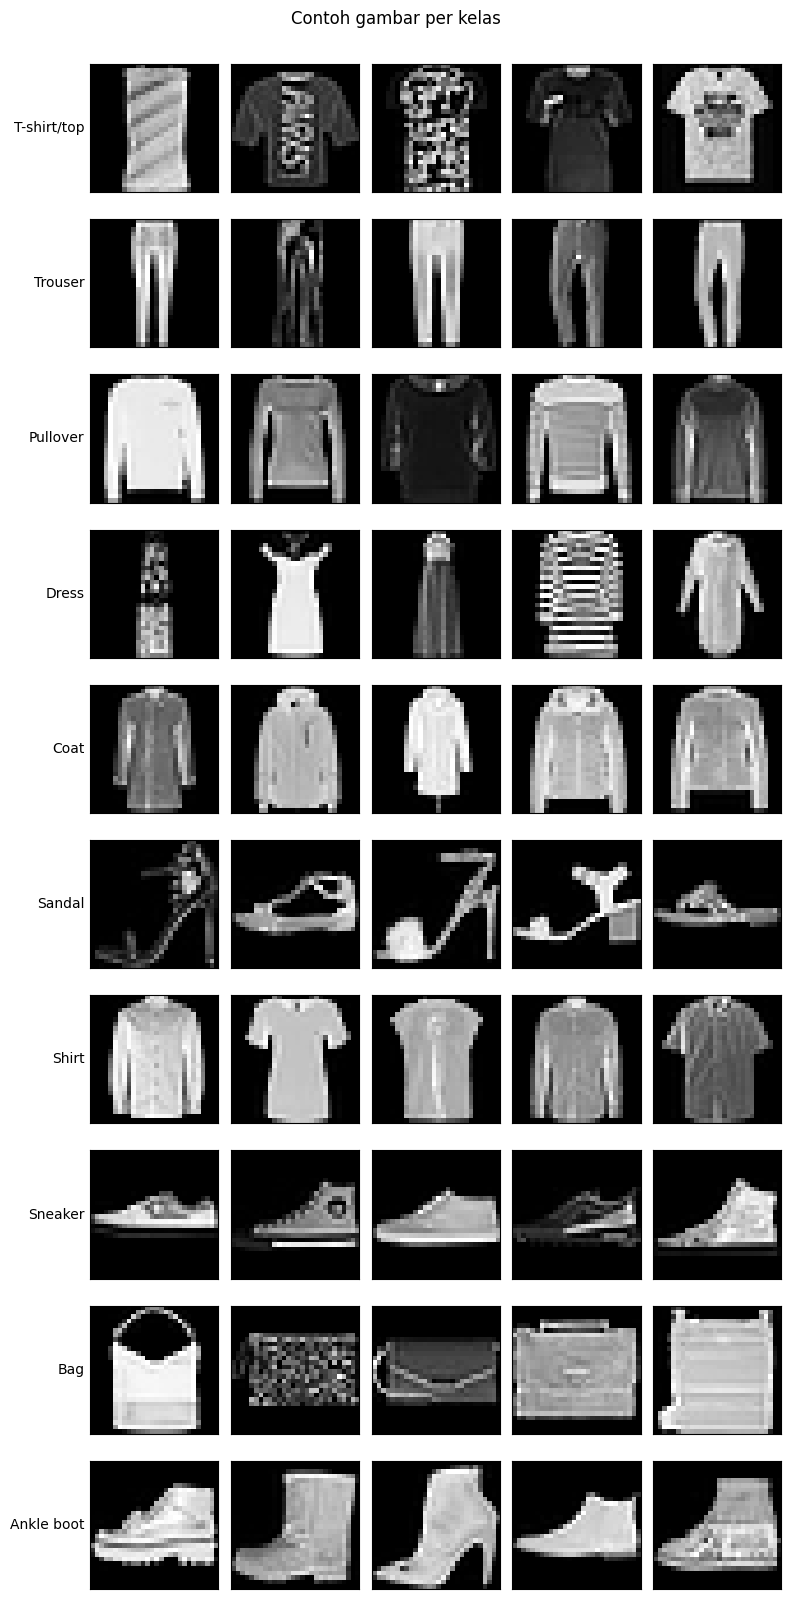

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

n_per_class = 5
fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.6, 10 * 1.6))
for c in range(10):
    samples = train_df[train_df["label"] == c].sample(n_per_class, random_state=42)
    for j in range(n_per_class):
        ax = axes[c, j]
        ax.imshow(samples.iloc[j, 1:].values.reshape(28, 28), cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(class_names[c], rotation=0, ha="right", va="center", fontsize=10)
plt.suptitle("Contoh gambar per kelas", y=1.0)
plt.tight_layout(); plt.show()

# Secara visual, kelas yang mirip: T-shirt/top, Pullover, Coat, dan Shirt (semua pakaian atasan
# dengan siluet serupa), serta Sandal, Sneaker, dan Ankle boot (alas kaki).

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [5]:
# EDA tambahan 1: cek missing value, duplikat, dan rentang nilai piksel
pixels = train_df.iloc[:, 1:]
print("Missing value train:", train_df.isnull().sum().sum(), "| test:", test_df.isnull().sum().sum())
print("Duplikat train:", train_df.duplicated().sum(), "| test:", test_df.duplicated().sum())
print("Rentang nilai piksel:", pixels.values.min(), "-", pixels.values.max())
print("Distribusi kelas test set:")
print(test_df["label"].value_counts().sort_index().rename(index=label_map))

Missing value train: 0 | test: 0


Duplikat train: 43 | test: 1
Rentang nilai piksel: 0 - 255
Distribusi kelas test set:
label
T-shirt/top    1000
Trouser        1000
Pullover       1000
Dress          1000
Coat           1000
Sandal         1000
Shirt          1000
Sneaker        1000
Bag            1000
Ankle boot     1000
Name: count, dtype: int64


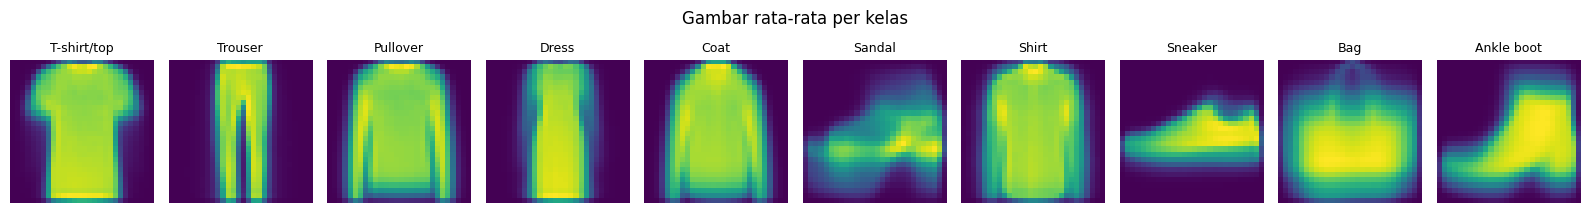

In [6]:
# EDA tambahan 2: gambar rata-rata tiap kelas
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for c in range(10):
    mean_img = train_df[train_df["label"] == c].iloc[:, 1:].values.mean(axis=0).reshape(28, 28)
    axes[c].imshow(mean_img, cmap="viridis")
    axes[c].set_title(class_names[c], fontsize=9); axes[c].axis("off")
plt.suptitle("Gambar rata-rata per kelas"); plt.tight_layout(); plt.show()
# Gambar rata-rata Pullover, Coat, dan Shirt sangat mirip (bentuk badan + lengan panjang),
# sedangkan Trouser dan Bag memiliki bentuk rata-rata yang khas.

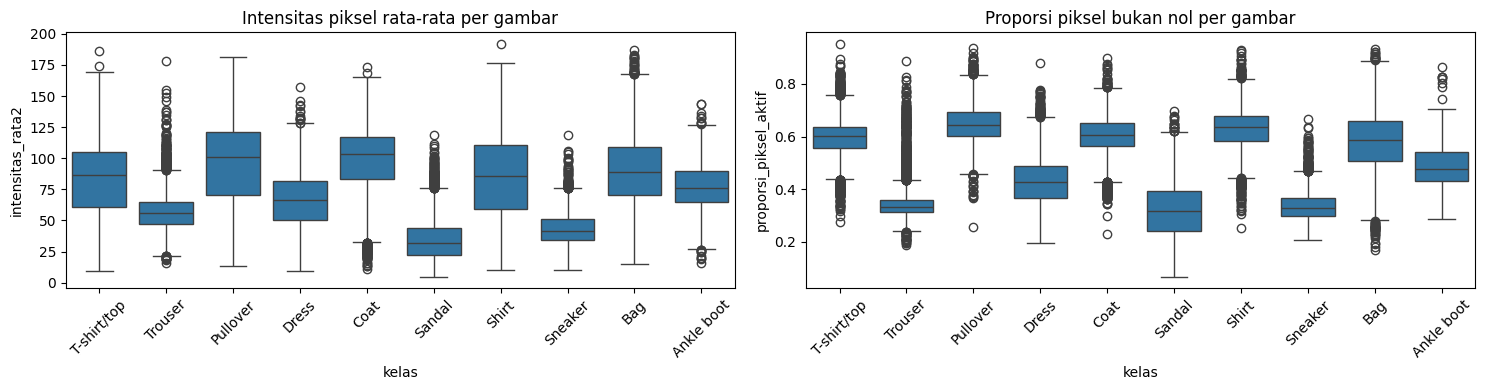

,intensitas_rata2,proporsi_piksel_aktif
kelas,,
Ankle boot,77.007,0.486
Bag,90.036,0.585
Coat,98.156,0.602
Dress,66.201,0.429
Pullover,95.719,0.649
Sandal,34.871,0.321
Shirt,85.115,0.629
Sneaker,42.836,0.338
T-shirt/top,82.879,0.595


In [7]:
# EDA tambahan 3: intensitas piksel rata-rata per gambar untuk tiap kelas
train_df_tmp = pd.DataFrame({
    "kelas": train_df["label"].map(label_map),
    "intensitas_rata2": train_df.iloc[:, 1:].values.mean(axis=1),
    "proporsi_piksel_aktif": (train_df.iloc[:, 1:].values > 0).mean(axis=1),
})
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=train_df_tmp, x="kelas", y="intensitas_rata2", ax=axes[0], order=class_names)
sns.boxplot(data=train_df_tmp, x="kelas", y="proporsi_piksel_aktif", ax=axes[1], order=class_names)
for ax in axes: ax.tick_params(axis="x", rotation=45)
axes[0].set_title("Intensitas piksel rata-rata per gambar")
axes[1].set_title("Proporsi piksel bukan nol per gambar")
plt.tight_layout(); plt.show()
display(train_df_tmp.groupby("kelas")[["intensitas_rata2", "proporsi_piksel_aktif"]].mean().round(3))
del train_df_tmp

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [8]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

X_train_full = train_df.drop(columns="label").values
y_train_full = train_df["label"].values
X_test = test_df.drop(columns="label").values
y_test = test_df["label"].values
print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test: (10000, 784) | y_test: (10000,)


In [9]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print("Rentang train:", X_train_full.min(), "-", X_train_full.max())
print("Rentang test :", X_test.min(), "-", X_test.max())

Rentang train: 0.0 - 1.0
Rentang test : 0.0 - 1.0


In [10]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=42)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (54000, 784) | Validation: (6000, 784) | Test: (10000, 784)


In [11]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

def to_tensor(X, y):
    return (torch.tensor(X, dtype=torch.float32).reshape(-1, 1, 28, 28),
            torch.tensor(y, dtype=torch.long))

X_train_t, y_train_t = to_tensor(X_train, y_train)
X_val_t, y_val_t = to_tensor(X_val, y_val)
X_test_t, y_test_t = to_tensor(X_test, y_test)

BATCH_SIZE = 128
g = torch.Generator().manual_seed(42)
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print("Bentuk X train:", X_train_t.shape, X_train_t.dtype, "| y train:", y_train_t.shape, y_train_t.dtype)
xb, yb = next(iter(train_loader))
print("Bentuk satu batch:", xb.shape, yb.shape)

del X_train_full, y_train_full, train_df  # hemat memori

Bentuk X train: torch.Size([54000, 1, 28, 28]) torch.float32 | y train: torch.Size([54000]) torch.int64
Bentuk satu batch: torch.Size([128, 1, 28, 28]) torch.Size([128])


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [12]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(42)
ann_model = ANN().to(device)
print(ann_model)
print("Jumlah parameter ANN:", count_params(ann_model))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146


In [13]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

EPOCHS = 15
LR = 1e-3

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
        # loss & accuracy dihitung ulang di mode eval agar train dan val sebanding
        tr_loss, tr_acc = evaluate(model, train_loader, criterion)
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
            history[k].append(v)
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - start:.1f}s")
    return history

torch.manual_seed(42)
ann_history = train_model(ann_model, train_loader, val_loader)

Epoch  1/15 | train loss 0.4416 acc 0.8426 | val loss 0.4624 acc 0.8357 | 1.3s


Epoch  2/15 | train loss 0.3660 acc 0.8668 | val loss 0.3915 acc 0.8562 | 1.3s


Epoch  3/15 | train loss 0.3410 acc 0.8771 | val loss 0.3726 acc 0.8655 | 1.4s


Epoch  4/15 | train loss 0.3191 acc 0.8830 | val loss 0.3636 acc 0.8652 | 1.4s


Epoch  5/15 | train loss 0.2744 acc 0.8998 | val loss 0.3219 acc 0.8790 | 1.4s


Epoch  6/15 | train loss 0.2918 acc 0.8887 | val loss 0.3505 acc 0.8692 | 1.4s


... (5 outputs left out)

Epoch 12/15 | train loss 0.2162 acc 0.9175 | val loss 0.3191 acc 0.8828 | 1.4s


Epoch 13/15 | train loss 0.2124 acc 0.9206 | val loss 0.3181 acc 0.8883 | 1.6s


Epoch 14/15 | train loss 0.2118 acc 0.9187 | val loss 0.3259 acc 0.8833 | 1.5s


Epoch 15/15 | train loss 0.1975 acc 0.9252 | val loss 0.3172 acc 0.8885 | 1.5s


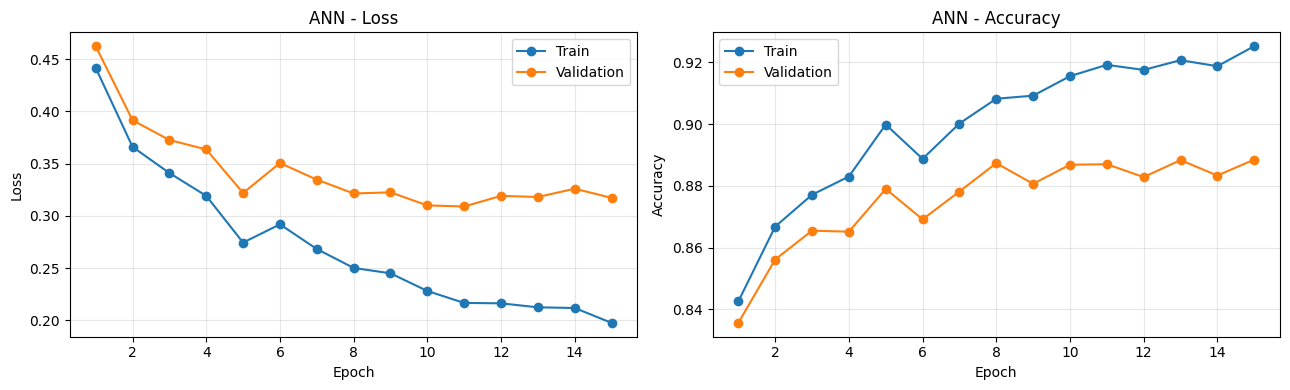

Val acc terbaik: 0.8885 (epoch 15) | gap train-val akhir: 0.0367


In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, history["train_loss"], "o-", label="Train")
    axes[0].plot(epochs, history["val_loss"], "o-", label="Validation")
    axes[0].set_title(f"{title} - Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[1].plot(epochs, history["train_acc"], "o-", label="Train")
    axes[1].plot(epochs, history["val_acc"], "o-", label="Validation")
    axes[1].set_title(f"{title} - Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    for ax in axes: ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    best = int(np.argmax(history["val_acc"]))
    print(f"Val acc terbaik: {history['val_acc'][best]:.4f} (epoch {best + 1}) | "
          f"gap train-val akhir: {history['train_acc'][-1] - history['val_acc'][-1]:.4f}")

plot_history(ann_history, "ANN")

In [15]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in loader:
            preds.append(model(x.to(device)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

ann_pred = predict(ann_model, test_loader)
print("Contoh prediksi:", ann_pred[:10])
print("Akurasi test ANN:", accuracy_score(y_test, ann_pred))

Contoh prediksi: [0 1 2 2 3 6 8 2 5 0]
Akurasi test ANN: 0.8927


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [16]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_model = SimpleCNN().to(device)
print(cnn_model)
print("Jumlah parameter CNN sederhana:", count_params(cnn_model))

# Perhitungan manual: (W - K + 2P) / S + 1
def out_size(W, K, P=0, S=1):
    return (W - K + 2 * P) // S + 1

w = 28
w = out_size(w, 3, 1, 1); print(f"Conv2d(1,32,3,p=1)  : (28 - 3 + 2) / 1 + 1 = {w}  -> (32, {w}, {w})")
w = out_size(w, 2, 0, 2); print(f"MaxPool2d(2)        : (28 - 2 + 0) / 2 + 1 = {w}  -> (32, {w}, {w})")
w = out_size(w, 3, 1, 1); print(f"Conv2d(32,64,3,p=1) : (14 - 3 + 2) / 1 + 1 = {w}  -> (64, {w}, {w})")
w = out_size(w, 2, 0, 2); print(f"MaxPool2d(2)        : (14 - 2 + 0) / 2 + 1 = {w}   -> (64, {w}, {w})")
print(f"Input Linear pertama = 64 x {w} x {w} = {64 * w * w}")

# Verifikasi dengan tensor dummy
with torch.no_grad():
    x = torch.zeros(1, 1, 28, 28).to(device)
    for layer in cnn_model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")
    print("Setelah Flatten:", tuple(x.flatten(1).shape))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN sederhana: 421642
Conv2d(1,32,3,p=1)  : (28 - 3 + 2) / 1 + 1 = 28  -> (32, 28, 28)
MaxPool2d(2)        : (28 - 2 + 0) / 2 + 1 = 14  -> (32, 14, 14)
Conv2d(32,64,3,p=1) : (14 - 3 + 2) / 1 + 1 = 14  -> (64, 14, 14)
MaxPool2d(2)        : (14 - 2 + 0) / 2 + 1 = 7   -> (64, 7, 7)
Input Linear pertama = 64 x 7 x 7 = 3136
Conv2d     -> (1, 32, 28, 28)
ReLU       -> (1, 32, 28, 

Epoch  1/15 | train loss 0.3615 acc 0.8707 | val loss 0.3781 acc 0.8690 | 26.9s


Epoch  2/15 | train loss 0.2895 acc 0.8960 | val loss 0.3097 acc 0.8910 | 25.0s


Epoch  3/15 | train loss 0.2535 acc 0.9079 | val loss 0.2813 acc 0.8992 | 27.8s


Epoch  4/15 | train loss 0.2280 acc 0.9183 | val loss 0.2628 acc 0.9037 | 25.4s


Epoch  5/15 | train loss 0.2128 acc 0.9218 | val loss 0.2576 acc 0.9057 | 27.6s


Epoch  6/15 | train loss 0.1962 acc 0.9284 | val loss 0.2471 acc 0.9098 | 30.5s


... (5 outputs left out)

Epoch 12/15 | train loss 0.1194 acc 0.9559 | val loss 0.2406 acc 0.9122 | 26.8s


Epoch 13/15 | train loss 0.0916 acc 0.9685 | val loss 0.2262 acc 0.9205 | 23.5s


Epoch 14/15 | train loss 0.0879 acc 0.9694 | val loss 0.2384 acc 0.9252 | 24.2s


Epoch 15/15 | train loss 0.0707 acc 0.9765 | val loss 0.2409 acc 0.9245 | 24.5s


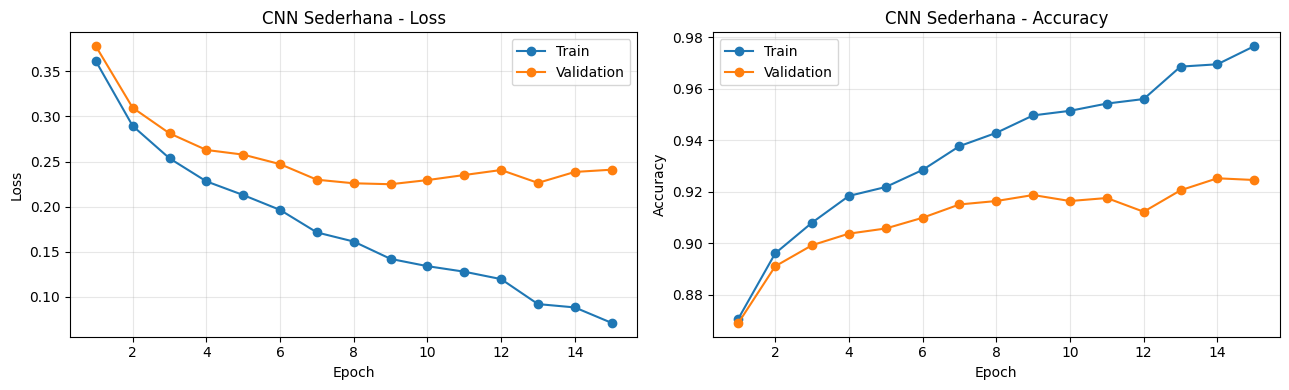

Val acc terbaik: 0.9252 (epoch 14) | gap train-val akhir: 0.0520


In [17]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

torch.manual_seed(42)
cnn_history = train_model(cnn_model, train_loader, val_loader)
plot_history(cnn_history, "CNN Sederhana")

In [18]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_pred = predict(cnn_model, test_loader)
print("Akurasi test CNN sederhana:", accuracy_score(y_test, cnn_pred))

Akurasi test CNN sederhana: 0.9264


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [19]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNN_BN_Dropout(nn.Module):
    def __init__(self, p_drop=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_bn_model = CNN_BN_Dropout().to(device)
print(cnn_bn_model)
print("Jumlah parameter CNN + BN + Dropout:", count_params(cnn_bn_model))
# model.train() dipanggil di awal setiap epoch dan model.eval() di dalam evaluate()/predict()

CNN_BN_Dropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BN + Dropout: 421834


Epoch  1/15 | train loss 0.3054 acc 0.8900 | val loss 0.3260 acc 0.8833 | 28.8s


Epoch  2/15 | train loss 0.2535 acc 0.9050 | val loss 0.2824 acc 0.8958 | 28.2s


Epoch  3/15 | train loss 0.2494 acc 0.9070 | val loss 0.2903 acc 0.8952 | 29.0s


Epoch  4/15 | train loss 0.2094 acc 0.9217 | val loss 0.2489 acc 0.9088 | 29.4s


Epoch  5/15 | train loss 0.1960 acc 0.9269 | val loss 0.2553 acc 0.9082 | 30.7s


Epoch  6/15 | train loss 0.1973 acc 0.9239 | val loss 0.2548 acc 0.9060 | 29.5s


... (5 outputs left out)

Epoch 12/15 | train loss 0.1326 acc 0.9503 | val loss 0.2377 acc 0.9137 | 29.0s


Epoch 13/15 | train loss 0.1188 acc 0.9561 | val loss 0.2381 acc 0.9173 | 28.6s


Epoch 14/15 | train loss 0.1136 acc 0.9573 | val loss 0.2464 acc 0.9140 | 30.8s


Epoch 15/15 | train loss 0.0891 acc 0.9667 | val loss 0.2370 acc 0.9218 | 28.6s


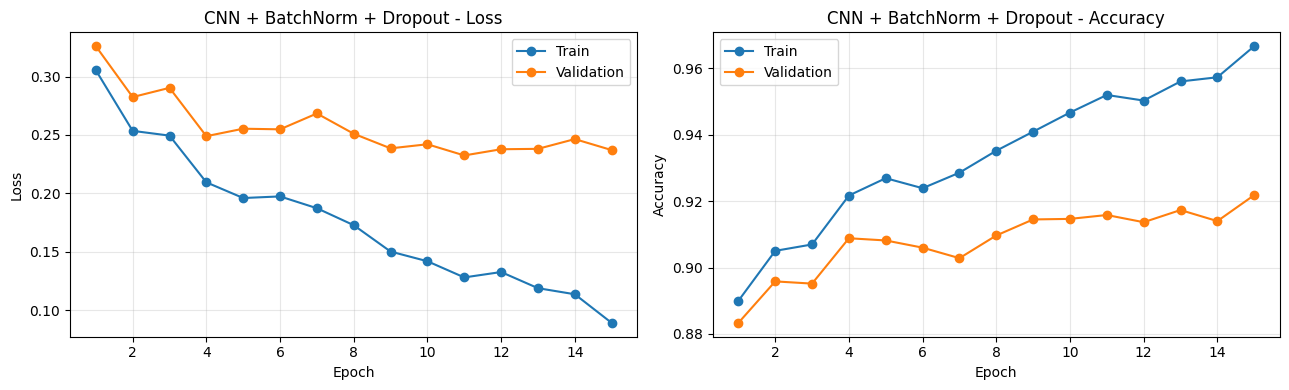

Val acc terbaik: 0.9218 (epoch 15) | gap train-val akhir: 0.0449


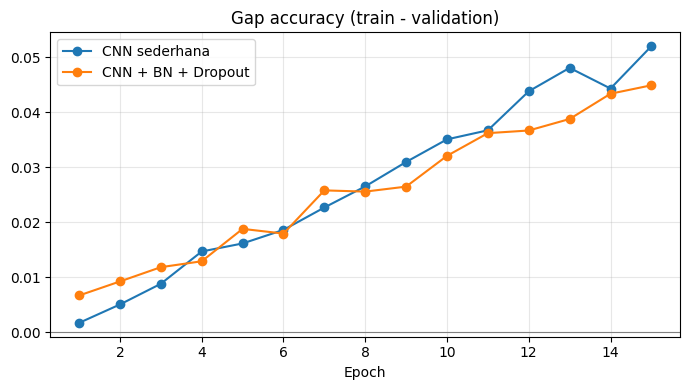

In [20]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

torch.manual_seed(42)
cnn_bn_history = train_model(cnn_bn_model, train_loader, val_loader)
plot_history(cnn_bn_history, "CNN + BatchNorm + Dropout")

# Perbandingan gap train-val antara CNN sederhana dan CNN+BN+Dropout
fig, ax = plt.subplots(figsize=(7, 4))
ep = range(1, EPOCHS + 1)
ax.plot(ep, np.array(cnn_history["train_acc"]) - np.array(cnn_history["val_acc"]), "o-", label="CNN sederhana")
ax.plot(ep, np.array(cnn_bn_history["train_acc"]) - np.array(cnn_bn_history["val_acc"]), "o-", label="CNN + BN + Dropout")
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Gap accuracy (train - validation)"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [21]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_bn_pred = predict(cnn_bn_model, test_loader)
print("Akurasi test CNN + BN + Dropout:", accuracy_score(y_test, cnn_bn_pred))

Akurasi test CNN + BN + Dropout: 0.9278


# 4. Evaluasi Model

In [22]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

models = {
    "ANN": (ann_model, ann_pred),
    "CNN Sederhana": (cnn_model, cnn_pred),
    "CNN + BN + Dropout": (cnn_bn_model, cnn_bn_pred),
}
rows = []
for name, (m, pred) in models.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1-Score (macro)": f1_score(y_test, pred, average="macro"),
        "Jumlah Parameter": count_params(m),
    })
results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.style.format({c: "{:.4f}" for c in results_df.columns[:-1]} | {"Jumlah Parameter": "{:,}"}))

best_name = results_df["F1-Score (macro)"].idxmax()
best_model, best_pred = models[best_name]
print("Model terbaik (berdasarkan F1 macro):", best_name)

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter
Model,,,,,
ANN,0.8927,0.8939,0.8927,0.8914,"235,146"
CNN Sederhana,0.9264,0.9266,0.9264,0.9264,"421,642"
CNN + BN + Dropout,0.9278,0.9275,0.9278,0.9275,"421,834"


Model terbaik (berdasarkan F1 macro): CNN + BN + Dropout


In [23]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

print(f"Classification report - {best_name}")
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Classification report - CNN + BN + Dropout
              precision    recall  f1-score   support

 T-shirt/top     0.8681    0.8750    0.8715      1000
     Trouser     0.9861    0.9940    0.9900      1000
    Pullover     0.9031    0.8850    0.8939      1000
       Dress     0.9382    0.9260    0.9321      1000
        Coat     0.8804    0.9200    0.8998      1000
      Sandal     0.9909    0.9780    0.9844      1000
       Shirt     0.8010    0.7690    0.7847      1000
     Sneaker     0.9640    0.9640    0.9640      1000
         Bag     0.9792    0.9870    0.9831      1000
  Ankle boot     0.9636    0.9800    0.9717      1000

    accuracy                         0.9278     10000
   macro avg     0.9275    0.9278    0.9275     10000
weighted avg     0.9275    0.9278    0.9275     10000



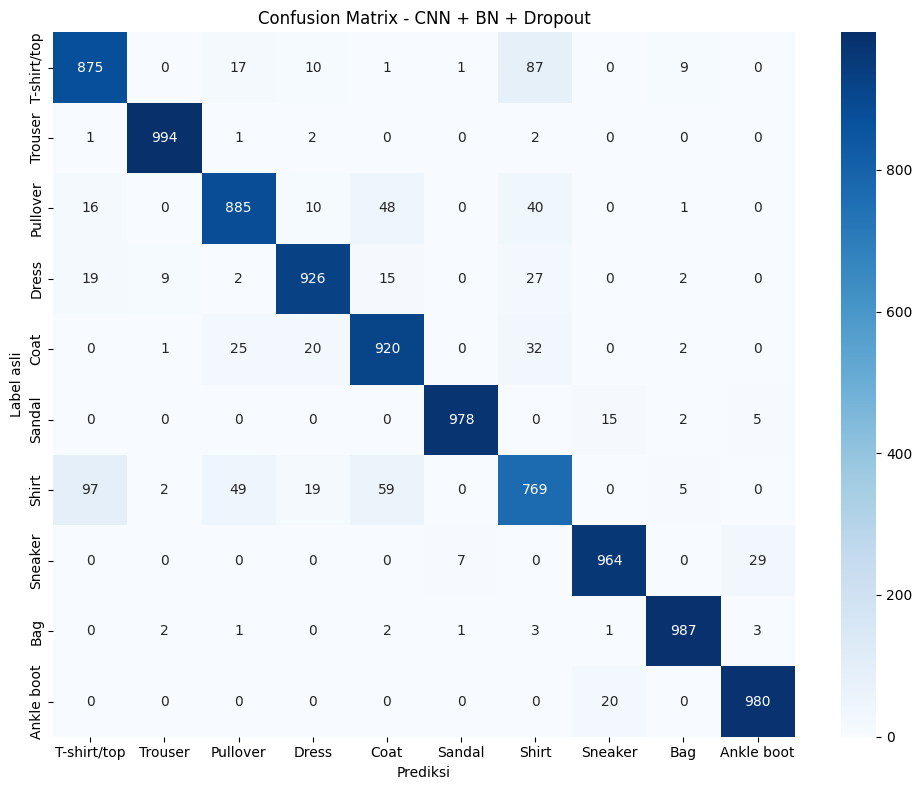

,Label asli,Prediksi,Jumlah
0,Shirt,T-shirt/top,97
1,T-shirt/top,Shirt,87
2,Shirt,Coat,59
3,Shirt,Pullover,49
4,Pullover,Coat,48
5,Pullover,Shirt,40
6,Coat,Shirt,32
7,Sneaker,Ankle boot,29


In [24]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Prediksi"); plt.ylabel("Label asli")
plt.tight_layout(); plt.show()

# Pasangan kelas yang paling sering tertukar (asli -> prediksi)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(class_names[i], class_names[j], cm_off[i, j]) for i in range(10) for j in range(10) if cm_off[i, j] > 0]
pairs_df = pd.DataFrame(pairs, columns=["Label asli", "Prediksi", "Jumlah"]).sort_values("Jumlah", ascending=False)
display(pairs_df.head(8).reset_index(drop=True))

**Pasangan kelas yang paling sering tertukar (model CNN + BN + Dropout):**

| Label asli → Prediksi | Jumlah |
|---|---|
| Shirt → T-shirt/top | 97 |
| T-shirt/top → Shirt | 87 |
| Shirt → Coat | 59 |
| Shirt → Pullover | 49 |
| Pullover → Coat | 48 |
| Pullover → Shirt | 40 |
| Coat → Shirt | 32 |
| Sneaker → Ankle boot | 29 |

Pasangan yang paling sering tertukar adalah **Shirt ↔ T-shirt/top** (total 184 kesalahan). Kelas **Shirt** menjadi pusat kebingungan karena tertukar dengan hampir semua kelas atasan lain (T-shirt/top, Coat, Pullover). Ini sesuai dengan temuan EDA: siluet keempat kelas atasan tersebut sangat mirip pada resolusi 28×28, dan detail pembeda (kerah, kancing, resleting, panjang lengan) hanya terlihat dari beberapa piksel. Di kelompok alas kaki, kesalahan terbanyak adalah Sneaker → Ankle boot (29).

Jumlah salah klasifikasi: 722 dari 10000


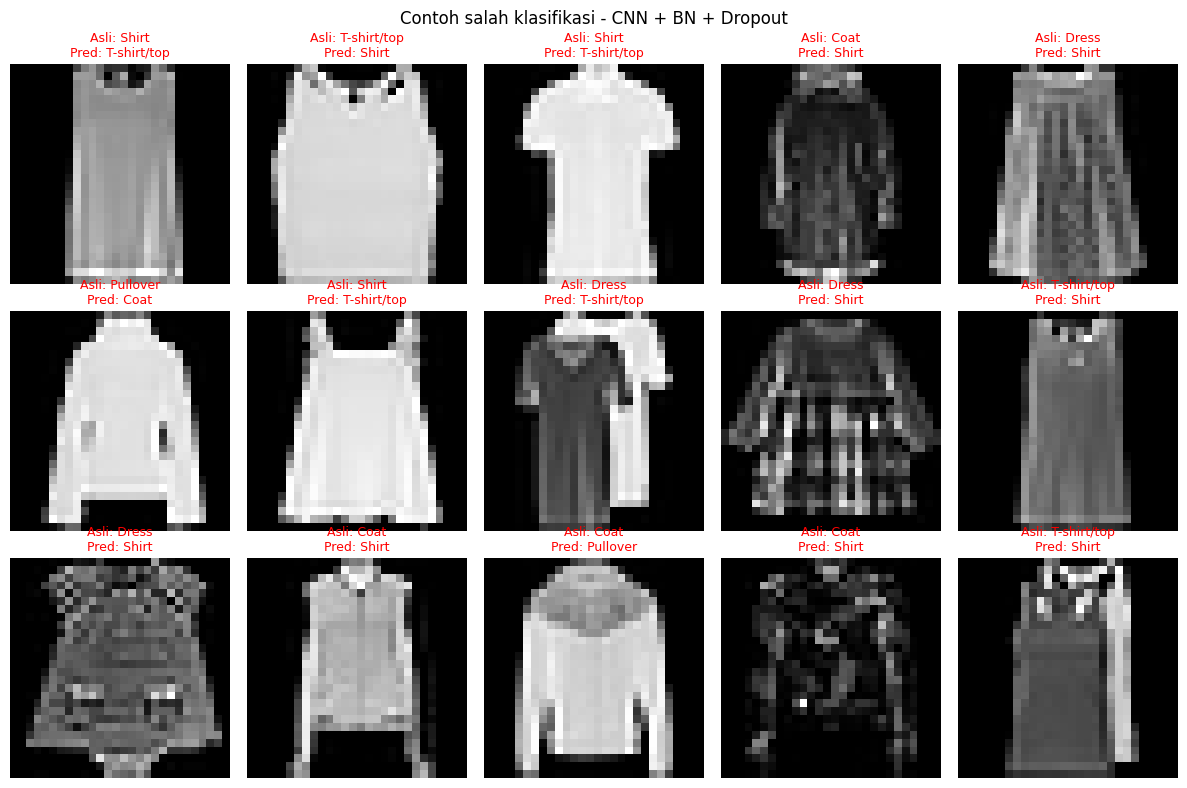

In [25]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

wrong_idx = np.where(best_pred != y_test)[0]
print(f"Jumlah salah klasifikasi: {len(wrong_idx)} dari {len(y_test)}")
rng = np.random.default_rng(42)
show = rng.choice(wrong_idx, size=15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[i]]}\nPred: {class_names[best_pred[i]]}", fontsize=9, color="red")
    ax.axis("off")
plt.suptitle(f"Contoh salah klasifikasi - {best_name}"); plt.tight_layout(); plt.show()

Gambar contoh: T-shirt/top | bentuk feature map: (32, 28, 28)


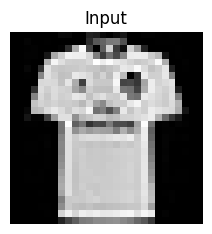

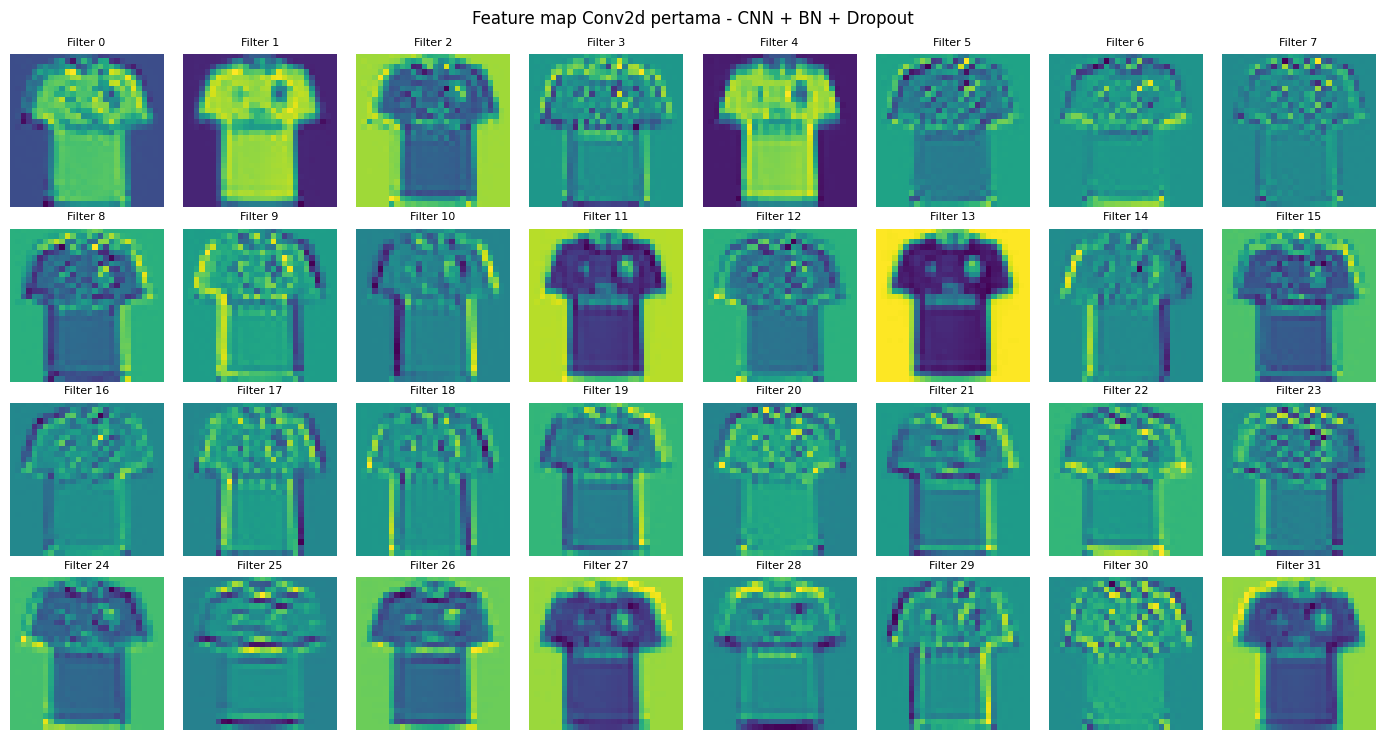

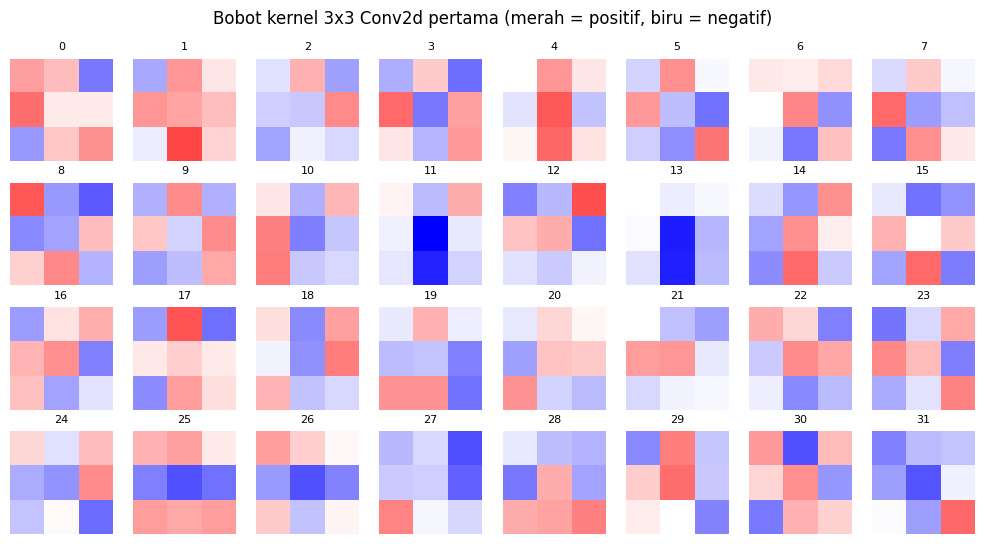

In [26]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

sample_idx = 0
x = X_test_t[sample_idx:sample_idx + 1].to(device)  # (1, 1, 28, 28)
best_model.eval()
with torch.no_grad():
    fmap = best_model.features[0](x)  # output Conv2d pertama: (1, 32, 28, 28)
fmap = fmap.detach().cpu().numpy()[0]
print("Gambar contoh:", class_names[y_test[sample_idx]], "| bentuk feature map:", fmap.shape)

plt.figure(figsize=(2.5, 2.5))
plt.imshow(X_test[sample_idx].reshape(28, 28), cmap="gray"); plt.title("Input"); plt.axis("off"); plt.show()

fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(fmap[c], cmap="viridis"); ax.set_title(f"Filter {c}", fontsize=8); ax.axis("off")
plt.suptitle(f"Feature map Conv2d pertama - {best_name}"); plt.tight_layout(); plt.show()

# Bobot filter 3x3 untuk membantu interpretasi
w = best_model.features[0].weight.detach().cpu().numpy()[:, 0]
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(w[c], cmap="bwr", vmin=-np.abs(w).max(), vmax=np.abs(w).max()); ax.set_title(f"{c}", fontsize=8); ax.axis("off")
plt.suptitle("Bobot kernel 3x3 Conv2d pertama (merah = positif, biru = negatif)"); plt.tight_layout(); plt.show()

**Interpretasi feature map Conv2d pertama** (gambar contoh: T-shirt/top):

- **Detektor area/siluet:** filter 0, 1, dan 4 (aktivasi tinggi di seluruh badan baju) serta kebalikannya filter 2, 11, dan 13 (aktivasi tinggi di latar belakang, rendah di baju). Filter ini memisahkan objek dari latar.
- **Detektor tepi vertikal:** filter 10, 14, 17, dan 18 menyala kuat di sisi kiri/kanan badan dan lengan. Kernel filter 11 dan 13 juga berupa kolom tengah bernilai negatif kuat, yaitu pola tepi vertikal.
- **Detektor tepi horizontal:** filter 22, 25, dan 28 menonjolkan batas atas bahu/kerah dan ujung bawah baju. Kernel filter 25 berbentuk baris tengah negatif yang diapit baris positif.
- **Detektor tepi diagonal/arah tertentu:** filter 9, 27, 29, dan 31 aktif pada salah satu sisi kontur (kiri atau kanan) dan pada garis bahu yang miring.
- **Detektor tekstur/detail:** filter 3, 5, 7, 23, dan 30 menangkap variasi kecil di dalam baju, misalnya motif/gambar di dada.

Layer pertama CNN mempelajari fitur tingkat rendah seperti siluet, tepi dengan berbagai orientasi, dan tekstur. Layer berikutnya menggabungkan fitur ini menjadi pola yang lebih kompleks (lengan, kerah, sol sepatu).

In [27]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")

model_classes = {"ANN": ANN, "CNN Sederhana": SimpleCNN, "CNN + BN + Dropout": CNN_BN_Dropout}
print(f"Bobot model terbaik ({best_name}, class {model_classes[best_name].__name__}) disimpan ke model.pth")

# Simpan definisi class model ke file .py agar dapat dipakai di tugas Deployment
model_def = """import torch.nn as nn


class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNN_BN_Dropout(nn.Module):
    def __init__(self, p_drop=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
"""
with open("model_def.py", "w") as f:
    f.write(model_def)
print("Definisi class model disimpan ke model_def.py")

# Uji muat ulang
import importlib, model_def as md
importlib.reload(md)
loaded = getattr(md, model_classes[best_name].__name__)().to(device)
loaded.load_state_dict(torch.load("model.pth", map_location=device))
print("Akurasi model yang dimuat ulang:", accuracy_score(y_test, predict(loaded, test_loader)))

Bobot model terbaik (CNN + BN + Dropout, class CNN_BN_Dropout) disimpan ke model.pth
Definisi class model disimpan ke model_def.py


Akurasi model yang dimuat ulang: 0.9278


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

### Hasil evaluasi pada test set (10.000 gambar)

| Model | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Parameter |
|---|---|---|---|---|---|
| ANN | 0.8927 | 0.8939 | 0.8927 | 0.8914 | 235.146 |
| CNN Sederhana | 0.9264 | 0.9266 | 0.9264 | 0.9264 | 421.642 |
| **CNN + BN + Dropout** | **0.9278** | **0.9275** | **0.9278** | **0.9275** | 421.834 |

Ketiga model dilatih dengan pengaturan yang sama (Adam, lr = 0.001, batch size 128, 15 epoch, seed 42, split 90:10 dengan stratify) agar perbandingannya adil.

**1. ANN vs CNN.** CNN sederhana menaikkan akurasi dari 89,27% menjadi 92,64% (+3,4 poin), atau mengurangi kesalahan dari 1.073 menjadi 736 gambar (turun sekitar 31%). Jumlah parameter CNN memang 1,8× lebih banyak, tetapi keunggulannya bukan sekadar karena ukurannya:
- ANN langsung mem-*flatten* gambar menjadi vektor 784 nilai sehingga informasi spasial (piksel mana yang bertetangga) hilang. Setiap neuron di layer pertama harus mempelajari pola untuk seluruh gambar sekaligus, sehingga pola yang sama di posisi berbeda harus dipelajari ulang.
- CNN memakai kernel 3×3 yang **berbagi bobot** di seluruh posisi gambar. Layer konvolusi hanya memiliki 320 + 18.496 parameter, tetapi mampu mendeteksi tepi, sudut, dan tekstur di mana pun letaknya. MaxPooling membuat fitur lebih tahan terhadap pergeseran kecil. Sebagian besar parameter CNN (401.536 atau ±95%) justru berada di `Linear(3136, 128)`, bukan di bagian konvolusi.
- Akibatnya, sejak epoch pertama CNN sudah mencapai val acc 86,9% (ANN 83,6%), dan validation loss terendah CNN (0,225) jauh di bawah ANN (0,309).

**2. Pengaruh Batch Normalization dan Dropout terhadap learning curve.**
- **Konvergensi lebih cepat:** dengan BN, val acc epoch pertama langsung 88,3% (CNN sederhana 86,9%) dan train loss awal lebih rendah (0,305 vs 0,362). BN menormalkan distribusi aktivasi tiap batch sehingga gradien lebih stabil.
- **Overfitting berkurang:** pada CNN sederhana, train acc terus naik hingga 97,65% dan train loss turun ke 0,071, sedangkan validation loss justru naik dari titik terendah 0,225 (epoch 9) menjadi 0,241 di epoch 15. Ini tanda awal overfitting, dengan gap train–val akhir sebesar 5,2 poin. Pada model BN + Dropout, train acc akhir lebih rendah (96,67%) karena Dropout (p = 0,5) mematikan setengah neuron secara acak saat training sehingga model tidak bisa menghafal data. Gap akhir mengecil menjadi 4,5 poin dan validation loss lebih datar (0,232–0,247).
- **Kurva validasi sedikit lebih fluktuatif** di epoch 5–7 karena statistik BN bergantung pada batch dan Dropout menambah noise saat training.
- **Dampak pada test set kecil:** akurasi hanya naik 0,14 poin (92,64% → 92,78%) dengan tambahan 192 parameter (γ dan β milik BN). Dengan 15 epoch, CNN sederhana belum overfit parah, sehingga manfaat regularisasi belum terlihat besar. Manfaat ini diperkirakan makin terasa jika training diperpanjang, karena CNN sederhana akan terus menghafal data training.

**3. Kelas yang sulit dibedakan.** Berdasarkan classification report model terbaik:
- **Mudah:** Trouser (F1 0,990), Sandal (0,984), Bag (0,983), Ankle boot (0,972), dan Sneaker (0,964). Bentuknya khas dan tidak punya "kembaran" visual, sesuai gambar rata-rata pada EDA.
- **Sulit:** **Shirt** (F1 0,785; recall hanya 76,9%), T-shirt/top (0,872), Pullover (0,894), dan Coat (0,900). Confusion matrix menunjukkan kesalahan terkonsentrasi di antara kelas atasan: Shirt ↔ T-shirt/top (184), Shirt → Coat (59), Shirt → Pullover (49), dan Pullover → Coat (48). Pada EDA, gambar rata-rata Pullover, Coat, dan Shirt nyaris identik, intensitas dan proporsi piksel aktifnya juga berdekatan (0,60–0,65). Di kelompok alas kaki, kebingungan terbesar adalah Sneaker → Ankle boot (29).
- Contoh gambar yang salah klasifikasi memperlihatkan bahwa sebagian kesalahan memang ambigu bahkan bagi manusia, misalnya kemeja lengan pendek yang terlihat seperti kaos, atau kemeja tebal yang mirip mantel.

**4. Feature map.** Filter di layer konvolusi pertama terbukti mempelajari pemisah objek–latar, tepi vertikal, tepi horizontal, tepi diagonal, dan tekstur. Fitur lokal seperti ini tidak bisa dipelajari secara efisien oleh ANN, dan inilah yang menjelaskan keunggulan CNN.

**Model terbaik:** CNN + BN + Dropout (F1 macro 0,9275), disimpan ke `model.pth` dengan definisi class di `model_def.py`.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan
1. **CNN jelas lebih unggul daripada ANN** untuk klasifikasi gambar Fashion-MNIST: akurasi naik dari 89,27% menjadi ±92,7% dan jumlah kesalahan turun ±31%. Penyebab utamanya adalah konvolusi yang mempertahankan struktur spasial dan berbagi bobot, bukan sekadar jumlah parameter yang lebih banyak.
2. **CNN + Batch Normalization + Dropout adalah model terbaik** (accuracy 92,78%, F1 macro 0,9275). BN mempercepat konvergensi di epoch awal, sedangkan Dropout memperkecil gap train–validation dan menahan kenaikan validation loss. Namun, peningkatan akurasi test dibanding CNN sederhana hanya kecil (+0,14 poin) pada 15 epoch.
3. **Kelas atasan (Shirt, T-shirt/top, Pullover, Coat) adalah sumber kesalahan utama.** Shirt menjadi kelas tersulit (F1 0,785) karena siluetnya mirip dengan tiga kelas atasan lain. Kelas dengan bentuk khas (Trouser, Bag, Sandal, Ankle boot) diklasifikasikan dengan F1 > 0,97.

### Saran
- **Data augmentation** (random horizontal flip, rotasi atau pergeseran kecil, random erasing) untuk menambah variasi data dan memperkuat regularisasi.
- **Arsitektur lebih dalam**, misalnya 3 blok konvolusi atau dua Conv2d per blok (gaya VGG), atau mengganti `Linear(3136, 128)` dengan Global Average Pooling untuk memangkas ±95% parameter.
- **Training lebih lama dengan early stopping dan learning rate scheduler** (ReduceLROnPlateau/CosineAnnealing), memilih bobot dengan validation loss terendah, bukan bobot di epoch terakhir.
- **Hyperparameter tuning:** nilai dropout, learning rate, batch size, serta penambahan Dropout2d/weight decay.
- **Fokus pada kelas atasan:** misalnya melatih model khusus untuk membedakan Shirt/T-shirt/Pullover/Coat, atau memakai ensemble beberapa CNN.
- Menjalankan training di **GPU** (eksperimen ini berjalan di CPU, ±25–30 detik per epoch untuk CNN) agar eksperimen di atas lebih cepat dicoba.